In [1]:
import sys
import os
sys.path.insert(0, r"D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda")  # ưu tiên folder custom
import pandas as pd
import pickle
from sdv.single_table import MAECTGANSynthesizer
import numpy as np
import csv
import torch
# In kết quả
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,matthews_corrcoef
from sklearn.metrics import average_precision_score
from utils import plot_normal_vs_abnormal_tsne, plot_normal_vs_abnormal_pca
import pandas as pd
import sdv
print(sdv.__file__)

import ctgan
print(ctgan.__file__)

def load_threshold(path):
    with open(path, "rb") as f:
        return pickle.load(f)
    

    

D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\sdv\__init__.py
D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\ctgan\__init__.py


In [2]:
percentage = 1.0
dataset = "nsl_kdd"
epochs = 200
best_epoch = 160
margin = 5.0
lamda = 0.1
type_mode="all_seed_42"



path_model=f"results/all_seed_42/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}/checkpoints"
path_data=f"results/all_seed_42/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}"
path_save=f"results/all_seed_42/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}/per_attack_results"
if not os.path.exists(path_save):
    os.makedirs(path_save)


X_test = pd.read_csv(f"{path_data}/{dataset}_X_test.csv")
y_test = pd.read_csv(f"{path_data}/{dataset}_y_test.csv")['label']
X_val_normal= pd.read_csv(f"{path_data}/{dataset}_X_val_normal.csv")
y_val_normal= pd.read_csv(f"{path_data}/{dataset}_y_val_normal.csv")['label']

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("X_val_normal shape:", X_val_normal.shape)
print("y_val_normal shape:", y_val_normal.shape)

model_file = f"{path_model}/MAE_{dataset}_epoch_{best_epoch}.pkl"
if not os.path.exists(model_file):
    print(f"Model file for epoch {best_epoch} does not exist: {model_file}")

synthesizer = MAECTGANSynthesizer.load(f'{path_model}/MAE_{dataset}_epoch_{best_epoch}.pkl')

avg_loss,threshold_re, threshold_z_0, threshold_95,threshold_99 = synthesizer.get_threshold_mae(X_val_normal)


print("Threshold_re:", threshold_re)
print("Threshold_z:", threshold_z_0)
print("Threshold_95:", threshold_95)
print("Threshold_99:", threshold_99)

X_test shape: (22544, 122)
y_test shape: (22544,)
X_val_normal shape: (13469, 122)
y_val_normal shape: (13469,)


c:\Users\Admin\anaconda3\envs\ctgan_env\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator BayesianGaussianMixture from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\sdv\_utils.py:284: SDV Version Warning: You are currently on SDV version 1.32.0 but this synthesizer was created on version None. The latest bug fixes and features may not be available for this synthesizer. To see these enhancements, create and train a new synthesizer on this version.
  warnings.warn(message, SDVVersionWarning)


Threshold_re: (np.float32(0.012478374), np.float32(0.006322891))
Threshold_z: (np.float32(0.20862107), np.float32(0.23121357))
Threshold_95: 0.27289763
Threshold_99: 0.74166644


In [3]:

import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

def evaluate_ids_metrics(
    y_true,
    scores,
    far_levels=(0.01, 0.10)
):
    """
    Compute IDS metrics:
    - AUC (%)
    - PR-AUC (%)
    - TPR@FAR = 1%, 10%

    Parameters
    ----------
    y_true : array-like
        Ground truth labels (0: normal, 1: attack)
    scores : array-like
        Anomaly scores (higher = more abnormal)
    far_levels : tuple
        FAR levels, e.g. (0.01, 0.10)

    Returns
    -------
    results : dict
        {
          "AUC": float,
          "PR-AUC": float,
          "TPR@FAR=1%": float,
          "TPR@FAR=10%": float
        }
    """

    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)

    results = {}

    # =========================
    # 1. AUC (%)
    # =========================
    if len(np.unique(y_true)) < 2:
        results["AUC"] = 0.0
    else:
        results["AUC"] = roc_auc_score(y_true, scores) * 100

    # =========================
    # 2. PR-AUC (%)
    # =========================
    results["PR-AUC"] = average_precision_score(y_true, scores) * 100

    # =========================
    # 3. TPR@FAR
    # =========================
    scores_normal = scores[y_true == 0]

    for far in far_levels:
        # threshold theo percentile của normal
        threshold = np.percentile(scores_normal, 100 * (1 - far))

        y_pred = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        tpr = tp / (tp + fn + 1e-12)

        results[f"TPR@FAR={int(far*100)}%"] = tpr * 100

    return results



def predict_and_evaluate(
    Z_norm_test,
    y_true,
    threshold,
    save_dir="results", 
    filename="test_results.csv",
    device="cuda" if torch.cuda.is_available() else "cpu",
    batch_size=128,
    k_std=3.0,
    mode="std" #"re" #"dist"    
):
    """
    AE-based anomaly detection evaluation
    - Predict anomaly using reconstruction error
    - Compute AUC, ACC, F1, Precision, Recall
    - Compute confusion matrix
    - Save everything to TXT
    """
    # -------------------------
    # Prediction
    # -------------------------
    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, filename)
    print(f"Latent errors shape: {Z_norm_test.shape}")
    #y_true = np.concatenate(y_true)
    
    if mode=="re":
        mu, std = threshold
        threshold_test = mu + k_std * std
    elif mode=="std":
        mu, std = threshold
        threshold_test = mu + k_std * std
    elif mode=="dist":
        threshold_test = threshold
    
    y_pred = (Z_norm_test > threshold_test).astype(int)
    print("y_pred_shape:", y_pred.shape )
    
    print("Predicted label distribution in test set:")
    labels, counts = np.unique(y_pred, return_counts=True)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} samples")
    
    
    
    y_true = (y_true != 0).astype(int)  # 0 = normal
    print("True label distribution in test set:")
    
    labels, counts = np.unique(y_true, return_counts=True)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} samples")

    # =========================
    # 3. METRICS
    # =========================
    unique_classes = np.unique(y_true)

    # AUC-ROC
    if len(unique_classes) < 2:
        auc = 0.0
    else:
        auc = roc_auc_score(y_true, Z_norm_test)

    # PR-AUC (Average Precision)
    if len(unique_classes) < 2:
        pr_auc = 0.0
    else:
        pr_auc = average_precision_score(y_true, Z_norm_test)

    # Threshold-based metrics (fixed threshold => y_pred đã có)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)  # [[TN, FP],[FN, TP]]
    tn, fp, fn, tp = cm.ravel()

    # FAR = FP/(FP+TN)
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # MDR = FN/(FN+TP)
    mdr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

    # MCC (fixed threshold)
    mcc = matthews_corrcoef(y_true, y_pred) if len(unique_classes) == 2 else 0.0
    
    results_df = pd.DataFrame({
    "Metric": [
        "Threshold",
        "AUC (ROC)",
        "PR-AUC",
        "FAR (FPR @ fixed thres)",
        "MDR (FNR @ fixed thres)",
        "ACC",
        "F1",
        "Precision",
        "Recall (TPR)",
        "MCC (fixed thres)"
    ],
    "Value": [
        threshold_test,
        auc,
        pr_auc,
        far,
        mdr,
        acc,
        f1,
        precision,
        recall,
        mcc
    ]
    })
    return results_df


In [4]:
#classify_test_data
print("Classify test data using MAE 95% error...")
test_re_loss, test_z_norm, test_y_true = synthesizer.get_score_mae(X_test, y_test)
results_df=predict_and_evaluate(
    Z_norm_test=test_z_norm,
    y_true=test_y_true,
    threshold=threshold_95,
    save_dir=path_data,
    filename=f"test_results_mae_95_epoch_{best_epoch}.csv",
    mode="dist"
)
results_df

Classify test data using MAE 95% error...
[Time] get_score_mae: 246.97 ms
Latent errors shape: (22544,)
y_pred_shape: (22544,)
Predicted label distribution in test set:
Label 0: 10610 samples
Label 1: 11934 samples
True label distribution in test set:
Label 0: 9711 samples
Label 1: 12833 samples


,Metric,Value
0,Threshold,0.272898
1,AUC (ROC),0.953555
2,PR-AUC,0.956825
3,FAR (FPR @ fixed thres),0.087324
4,MDR (FNR @ fixed thres),0.136133
5,ACC,0.884892
6,F1,0.895223
7,Precision,0.928943
8,Recall (TPR),0.863867
9,MCC (fixed thres),0.770390


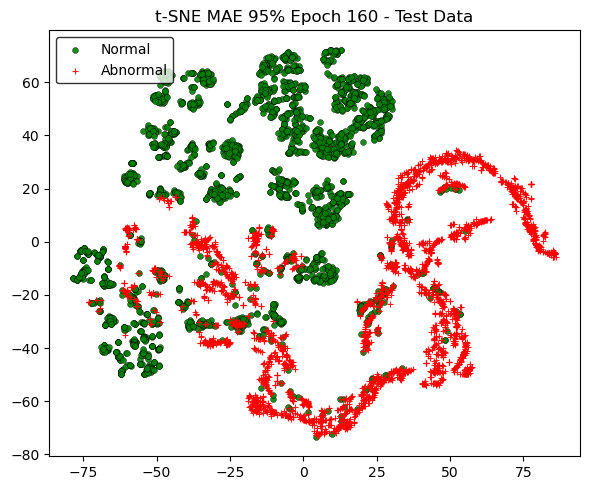

In [5]:
#tnse TEST DATA
z= synthesizer.get_latent_z_mae(X_test)
plot_normal_vs_abnormal_tsne(
    z[test_y_true==0],
    z[test_y_true!=0],
    title=f"t-SNE MAE 95% Epoch {best_epoch} - Test Data",
    save_path=f"{path_data}/tsne_Z_epoch_{best_epoch}_test.png",
    perplexity=30,
    learning_rate="auto",
    n_iter=1000, 
    random_state=42,
)




##1. Xử lý với Bot attack

In [6]:
def load_data_nsl_kdd_per_attack():
    import os
    import pandas as pd
    import numpy as np

    fileDir = os.path.dirname(os.path.abspath("__file__"))
    pathTrain = os.path.join(fileDir, "./data/NSLKDD/NSLKDD_Train.csv")
    pathTest = os.path.join(fileDir, "./data/NSLKDD/NSLKDD_Test.csv")

    TrainData = pd.read_csv(pathTrain, header=None)
    TestData = pd.read_csv(pathTest, header=None)

    # Clean
    TrainData.replace([np.inf, -np.inf], np.nan, inplace=True)
    TrainData.dropna(inplace=True)

    TestData.replace([np.inf, -np.inf], np.nan, inplace=True)
    TestData.dropna(inplace=True)

    print("train size", TrainData.shape)
    print("test size", TestData.shape)

    # =========================
    # Lấy label (đã là số)
    # =========================
    y_train = TrainData.iloc[:, -1].astype(int)
    y_test = TestData.iloc[:, -1].astype(int)

    # Features
    X_train = TrainData.iloc[:, 0:-1]
    X_test = TestData.iloc[:, 0:-1]

    # Full dataset
    X_full = pd.concat([X_train, X_test], ignore_index=True)
    y_full = pd.concat([y_train, y_test], ignore_index=True)

    # =========================
    # Lấy sample theo từng label
    # =========================
    labels = sorted(y_test.unique().astype(int).tolist())

    samples_by_attack = {}
    for label in labels:
        samples_by_attack[label] = X_test[y_test == label]

    print("Number of attack classes:", len(labels))
    print("Labels:", labels)

    # In số lượng mỗi attack
    for label in labels:
        print(f"Attack {label}: {len(samples_by_attack[label])} samples")

    return X_full, y_full, samples_by_attack, labels

In [ ]:
_,_,test_samples_by_label, test_labels=load_data_nsl_kdd_per_attack()

X_test = pd.read_csv(f"{path_data}/{dataset}_X_test.csv")


print (test_labels)

rows = []
x_test_normal=None
y_test_normal=None
for attack_index in test_labels:
    if attack_index ==0:
        x_test_normal=test_samples_by_label[attack_index]
        y_test_normal=np.zeros(len(x_test_normal),dtype=int)
print("Sample normal",len(x_test_normal))

for attack_index in test_labels:
    print(f"\n\n===========================Processing attack: {attack_index}===========================")
    if attack_index ==0:
        continue
    
    X_attack= test_samples_by_label[attack_index]
    print("Samples of attack: ",attack_index," : ",len(X_attack))
    y_attack = np.ones(len(X_attack), dtype=int)  # all abnormal = 1

    X_combined = pd.concat([x_test_normal, X_attack], ignore_index=True)
    y_combined = np.concatenate([y_test_normal, y_attack])
    X_combined.columns = [str(i) for i in range(X_combined.shape[1])]
    print("X combile: ",len(X_combined), " y_combined: ",len(y_combined))

    #classify_test_data
    print(f"Classify test attack: {attack_index} using MAE 95% error...")
    test_re_loss, test_z_norm, test_y_true = synthesizer.get_score_mae(X_combined, y_combined)
    metrics = evaluate_ids_metrics(y_combined, test_z_norm)
    row = {
        "Dataset": dataset,
        "Attack": attack_index,
        "Model": "SSAE",
        **metrics
    }
    rows.append(row)
df = pd.DataFrame(rows)
display(df)
df.to_csv(f"{path_save}/results_unsw_per_attack.csv", index=False)
    



train size (125973, 123)
test size (22544, 123)
Number of attack classes: 5
Labels: [0, 1, 2, 3, 4]
Attack 0: 9711 samples
Attack 1: 2421 samples
Attack 2: 7458 samples
Attack 3: 2887 samples
Attack 4: 67 samples
[0, 1, 2, 3, 4]
Sample normal 9711


===========================Processing attack: 0===========================


===========================Processing attack: 1===========================
Samples of attack:  1  :  2421
X combile:  12132  y_combined:  12132
Classify test attack: 1 using MAE 95% error...
[Time] get_score_mae: 133.41 ms


===========================Processing attack: 2===========================
Samples of attack:  2  :  7458
X combile:  17169  y_combined:  17169
Classify test attack: 2 using MAE 95% error...
[Time] get_score_mae: 171.87 ms


===========================Processing attack: 3===========================
Samples of attack:  3  :  2887
X combile:  12598  y_combined:  12598
Classify test attack: 3 using MAE 95% error...
[Time] get_score_mae: 117.99 ms


,Dataset,Attack,Model,AUC,PR-AUC,TPR@FAR=1%,TPR@FAR=10%
0,nsl_kdd,1,SSAE,95.888327,75.921531,16.646014,98.884758
1,nsl_kdd,2,SSAE,97.190036,95.659216,50.777688,95.870206
2,nsl_kdd,3,SSAE,89.872276,64.683044,6.581226,69.553169
3,nsl_kdd,4,SSAE,93.124430,5.339032,11.940299,85.074627
